In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
df_meteo = pd.read_parquet("../data/processed/datos_meteo_Valencia_91-25(month).parquet")
df_meteo.head()

,temp_med_mar (Cº),temp_med_mes (Cº),temp_med_max (Cº),temp_med_min (Cº),temp_abs_max (Cº),temp_abs_min (Cº),dias_temp>30,total_precip_mes (mm),precip_max (mm),dias_precip>10mm,dias_precip>30mm,dias_lluvia,dias_granizo,dias_tormenta,humedad_med (%),presion_max (hPa),presion_min (hPa),presion_med (hPa),viento_vel_max (km/h),viento_vel_med (km/h)
1991-01,13.6,11.1,15.3,6.8,22.5,1.2,0,104.2,32.4,3,2,7,1,1,74.580645,1030.4,1013.4,1022.179301,45.4,20.441801
1991-02,12.5,10.9,15.1,6.6,21.5,0.4,0,67.7,29.5,2,0,7,0,1,74.302083,1028.3,997.6,1014.741815,49.9,19.540625
1991-03,13.4,14.5,18.9,10.1,26.6,6.0,0,82.7,46.0,2,1,15,0,0,76.641129,1025.8,984.3,1009.190591,40.3,16.776747
1991-04,14.5,14.7,19.5,9.8,24.5,5.6,0,37.5,14.9,2,0,10,0,1,70.225000,1023.7,999.2,1013.787639,52.7,16.190417
1991-05,16.5,16.2,21.3,11.0,27.5,6.0,0,21.3,5.4,0,0,8,0,1,66.404570,1030.7,1004.2,1015.025538,30.9,12.288844


In [4]:
matriz_otonio = df_meteo[df_meteo.index.month.isin([8, 9, 10, 11, 12])]

df_anual_temporada = matriz_otonio.groupby(matriz_otonio.index.year).agg(
  # --- Precipitación y extremos ---
    precip_media_anual=('total_precip_mes (mm)', 'mean'),
    precip_max_anual=('total_precip_mes (mm)', 'max'),
    media_dias_precip_extrema_anual=('dias_precip>30mm', 'mean'),
    media_dias_lluvia_anual=('dias_lluvia', 'mean'),
    media_dias_tormenta_anual=('dias_tormenta', 'mean'),
    
    # --- Variables termodinámicas ---
    temp_mar_anual=('temp_med_mar (Cº)', 'mean'),
    temp_aire_anual=('temp_med_mes (Cº)', 'mean'),
    
    # --- Dinámica atmosférica y marina ---
    media_humedad_anual=('humedad_med (%)', 'mean'),
    media_presion_anual=('presion_med (hPa)', 'mean'),
    presion_max_anual=('presion_max (hPa)', 'max'),
    presion_min_anual=('presion_min (hPa)', 'min'),
    media_vel_viento_anual=('viento_vel_med (km/h)', 'mean')
)

df_anual_temporada

df_anual_temporada["decada"] = df_anual_temporada.index//10*10


df_decadal = df_anual_temporada.groupby('decada').agg(
    # --- Lluvias y extremos (Medias de la década y Récords absolutos) ---
    precip_media_decenal=('precip_media_anual', 'mean'),
    maximo_absoluto_precip=('precip_max_anual', 'max'), # El récord de lluvia de toda la década
    dias_lluvia_extremos_decenal=('media_dias_precip_extrema_anual', 'mean'),
    dias_lluvia_decenal=('media_dias_lluvia_anual', 'mean'),
    dias_tormenta_decenal=('media_dias_tormenta_anual', 'mean'),
    
    # --- Termodinámica (Evolución del calentamiento) ---
    temp_mar_decenal=('temp_mar_anual', 'mean'),
    temp_aire_decenal=('temp_aire_anual', 'mean'),
    
    # --- Dinámica atmosférica ---
    humedad_decenal=('media_humedad_anual', 'mean'),
    presion_media_decenal=('media_presion_anual', 'mean'),
    presion_max_decenal=('presion_max_anual', 'max'),
    presion_min_decenal=('presion_min_anual', 'min'), # El récord de baja presión (mínimas) de la década
    viento_decenal=('media_vel_viento_anual', 'mean')
)

df_decadal

,precip_media_decenal,maximo_absoluto_precip,dias_lluvia_extremos_decenal,dias_lluvia_decenal,dias_tormenta_decenal,temp_mar_decenal,temp_aire_decenal,humedad_decenal,presion_media_decenal,presion_max_decenal,presion_min_decenal,viento_decenal
decada,,,,,,,,,,,,
1990,43.695556,163.4,0.2,7.955556,1.844444,21.211111,19.484444,71.245547,1014.497790,1035.2,984.9,15.110872
2000,58.282000,336.9,0.36,8.100000,0.900000,21.642000,19.634000,70.538653,1014.556215,1037.4,986.3,14.830664
2010,46.932000,201.6,0.36,6.200000,0.560000,22.126000,20.116000,70.013480,1015.011328,1035.2,986.1,14.651805
2020,49.490000,250.1,0.366667,7.200000,1.766667,22.293333,20.780000,66.652851,1014.824028,1038.4,986.1,16.893056


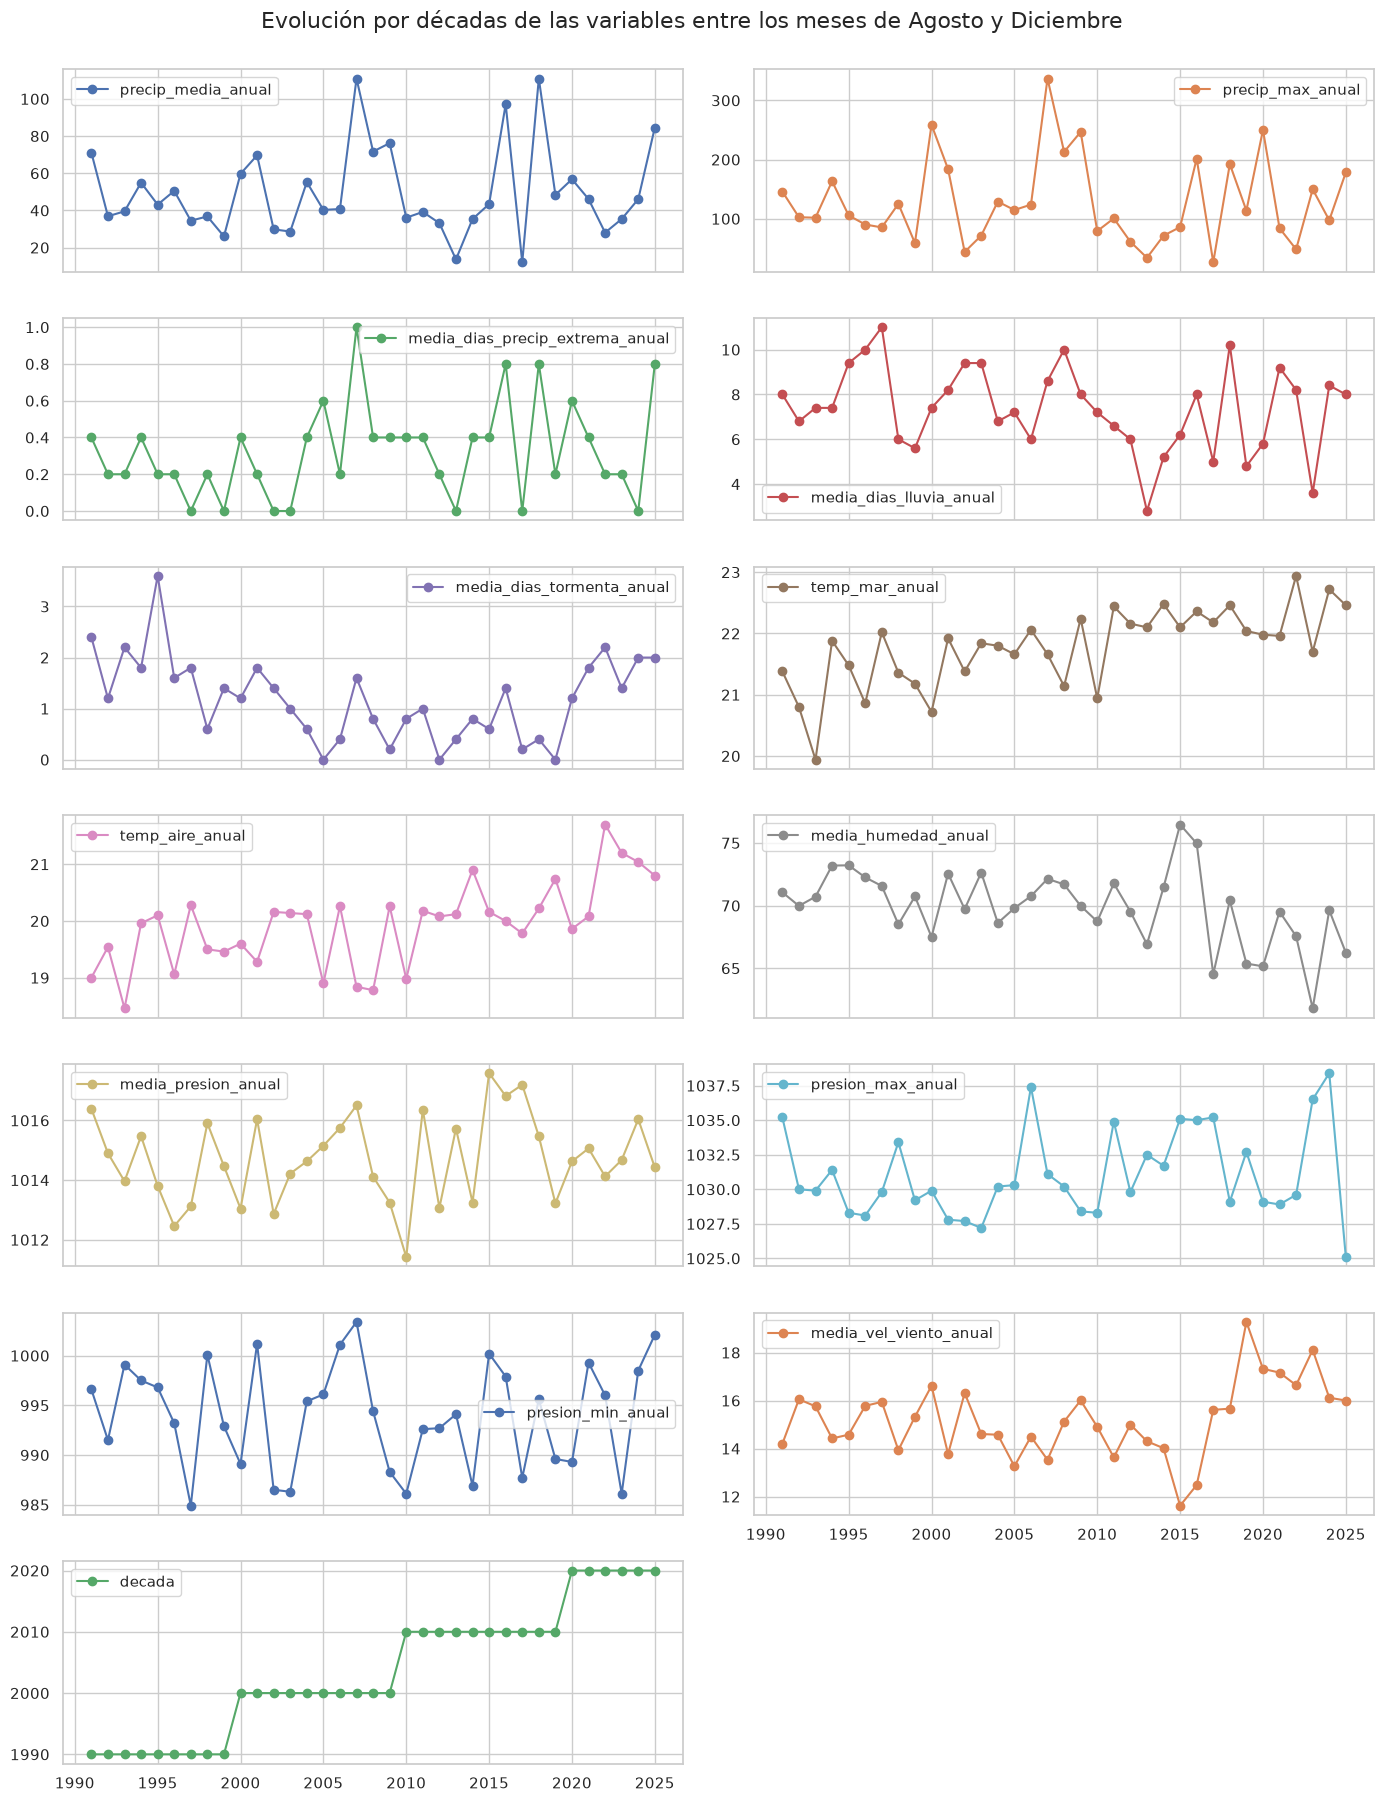

In [5]:
df_anual_temporada.plot(
    kind="line", 
    subplots=True, 
    layout=(-1, 2), 
    figsize=(14, 18), 
    marker="o",      # Pone un puntito en cada año para que se vea claro
    grid=True,       # Añade cuadrícula para facilitar la lectura
    sharex=True      # Comparte el eje X (los años) para no repetir números
)

plt.suptitle("Evolución por décadas de las variables entre los meses de Agosto y Diciembre", fontsize=16, y=1)
plt.tight_layout()
plt.show()

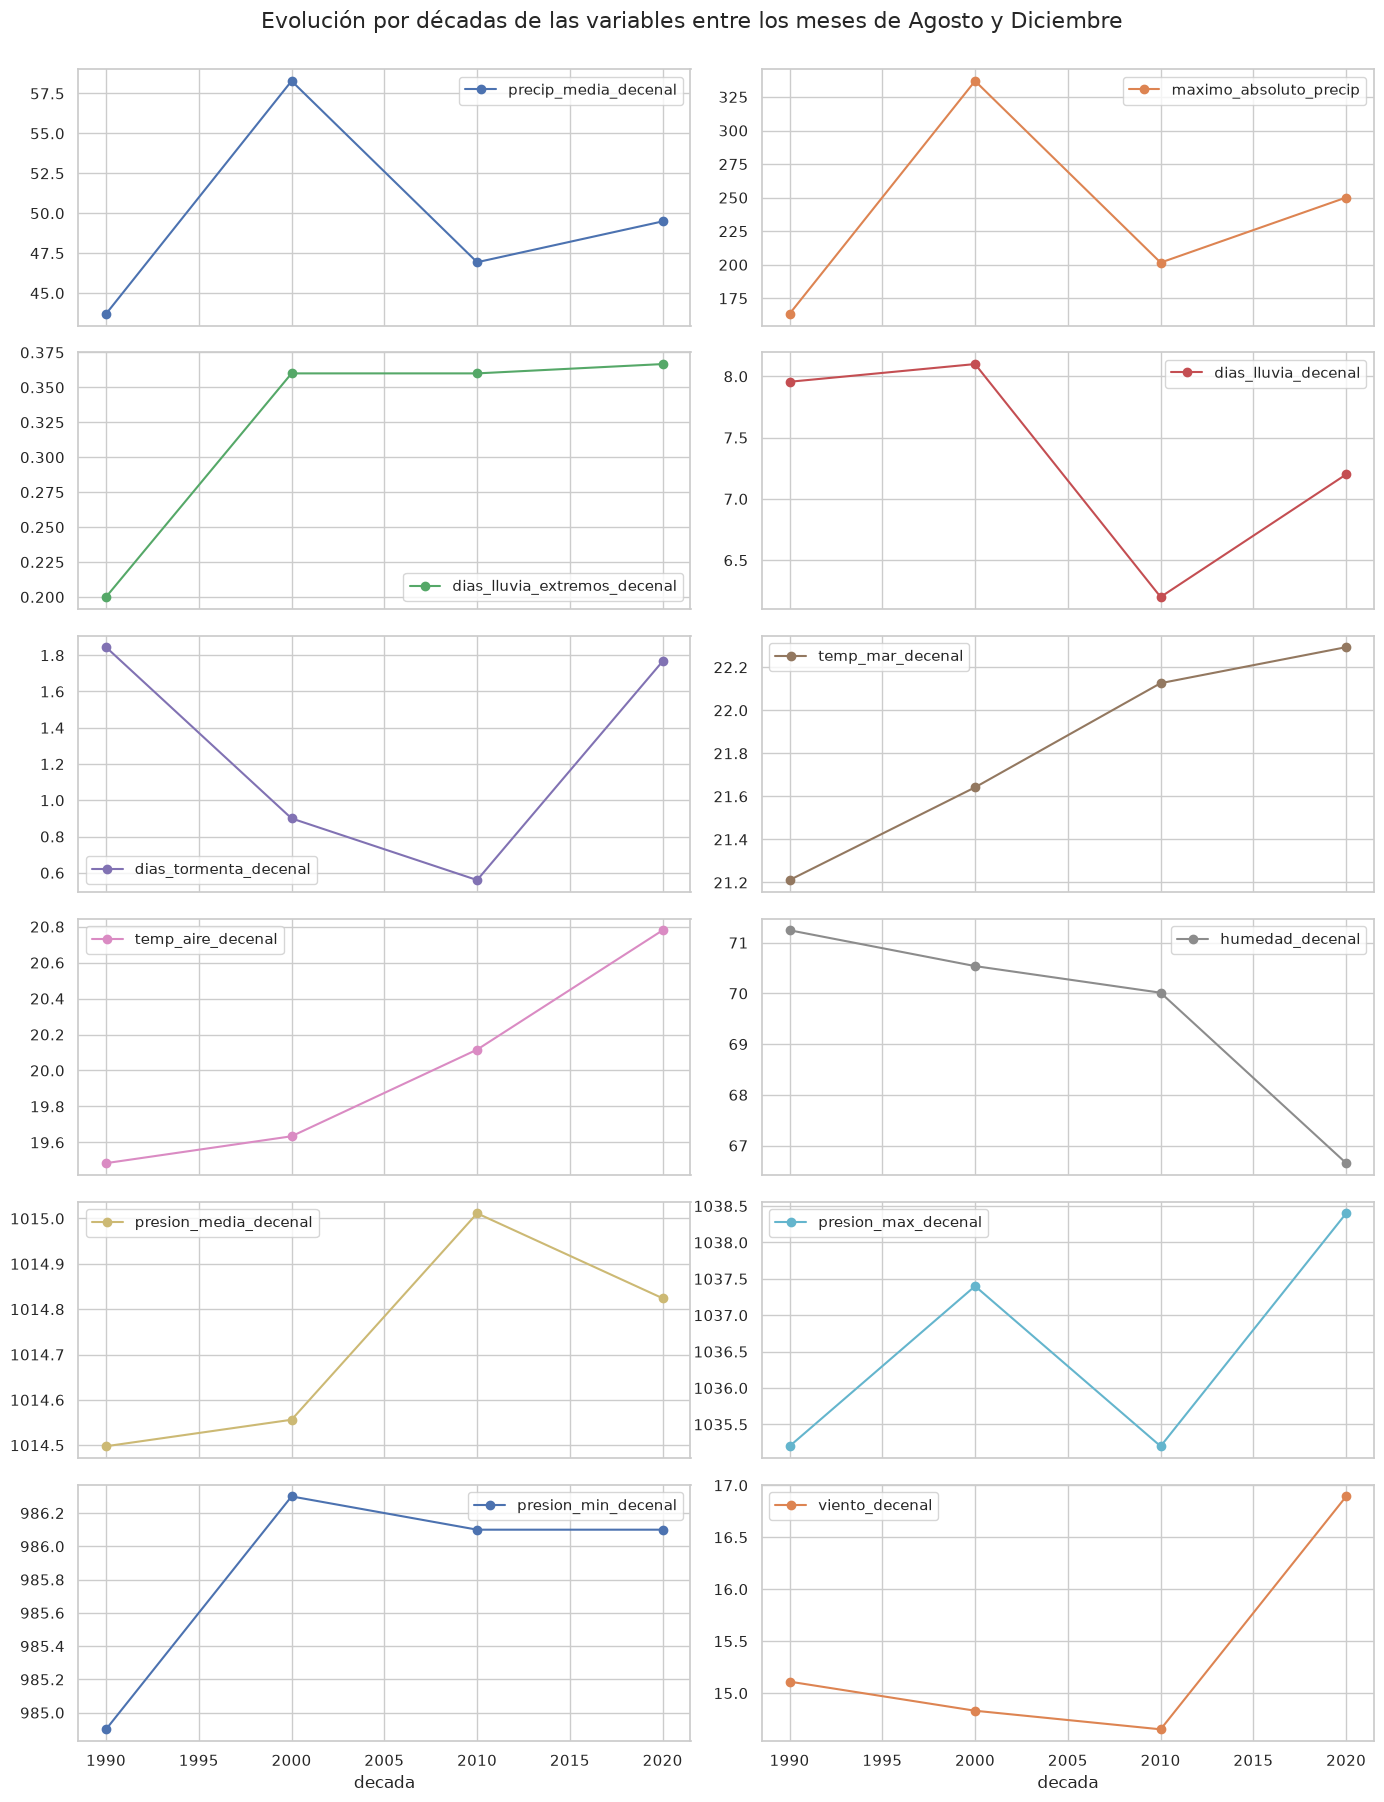

In [6]:
df_decadal.plot(
    kind="line", 
    subplots=True, 
    layout=(-1, 2), 
    figsize=(14, 18), 
    marker="o",      # Pone un puntito en cada año para que se vea claro
    grid=True,       # Añade cuadrícula para facilitar la lectura
    sharex=True      # Comparte el eje X (los años) para no repetir números
)

plt.suptitle("Evolución por décadas de las variables entre los meses de Agosto y Diciembre", fontsize=16, y=1)
plt.tight_layout()
plt.show()

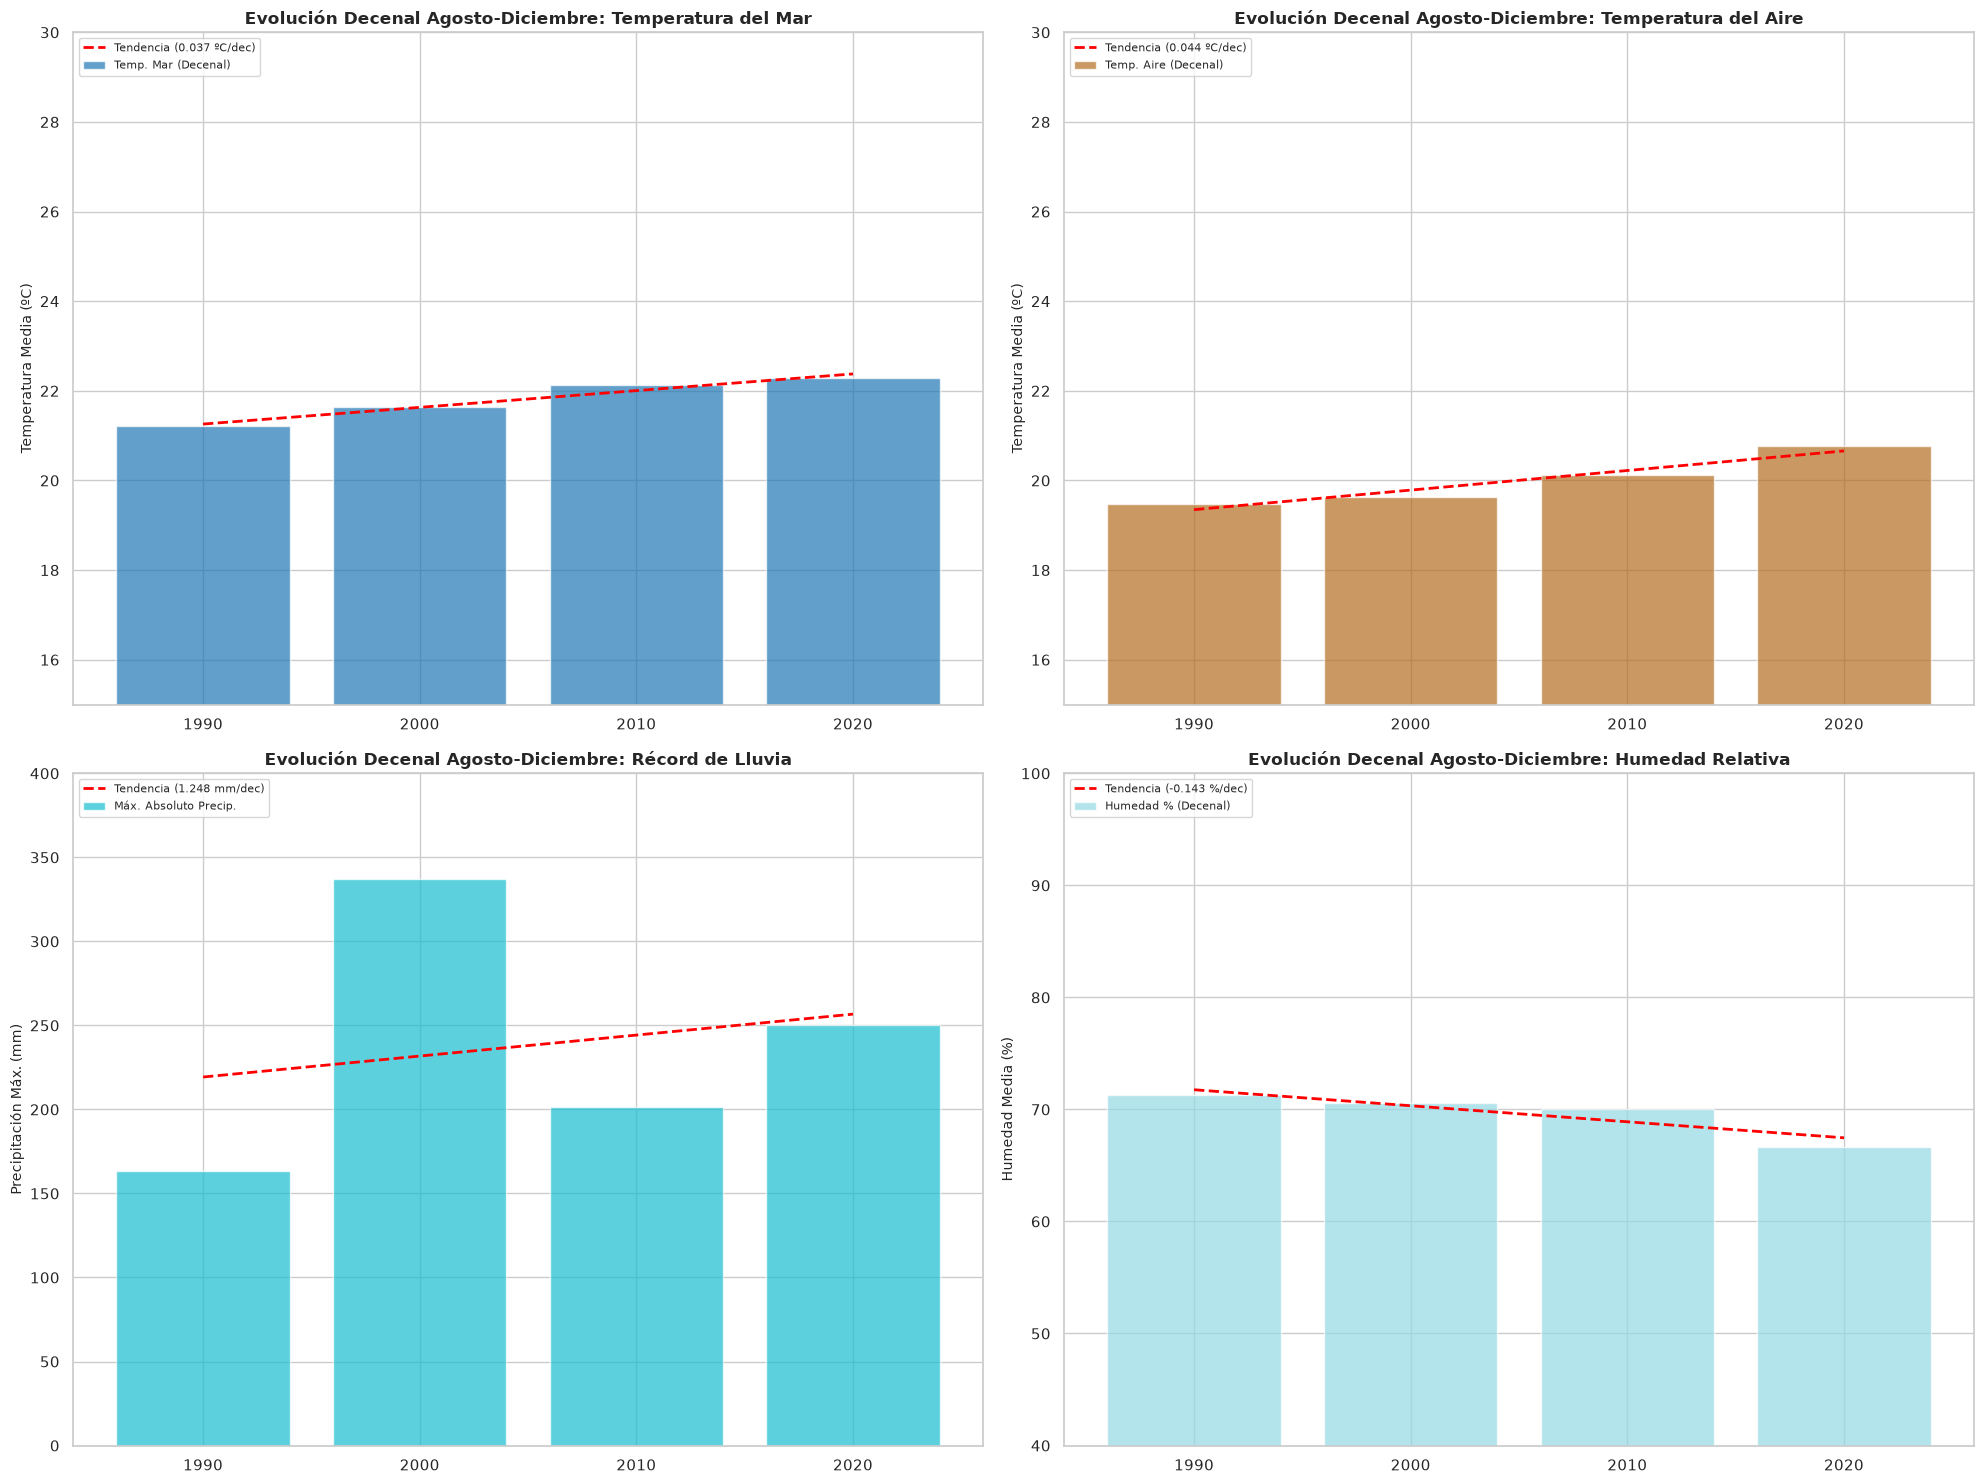

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Creamos una figura grande para alojar los 12 paneles (6 filas x 2 columnas)
fig = plt.figure(figsize=(20, 15))
grid_size = fig.add_gridspec(2, 2)
sns.set_theme(style="whitegrid")

# Definimos la configuración de los 12 paneles basada en tus variables decenales
paneles_config = [
    {
        'pos': (0, 0),
        'columna_y': 'temp_mar_decenal',
        'color': '#1f77b4',
        'label_bar': 'Temp. Mar (Decenal)',
        'titulo': 'Evolución Decenal Agosto-Diciembre: Temperatura del Mar',
        'ylabel': 'Temperatura Media (ºC)',
        'ylim': (15, 30),
        'tendencia_unidad': 'ºC/dec'
    },
    {
        'pos': (0, 1),
        'columna_y': 'temp_aire_decenal',
        'color': '#b46c1f',
        'label_bar': 'Temp. Aire (Decenal)',
        'titulo': 'Evolución Decenal Agosto-Diciembre: Temperatura del Aire',
        'ylabel': 'Temperatura Media (ºC)',
        'ylim': (15, 30),
        'tendencia_unidad': 'ºC/dec'
    },
    {
        'pos': (1, 0),
        'columna_y': 'maximo_absoluto_precip',
        'color': '#17becf',
        'label_bar': 'Máx. Absoluto Precip.',
        'titulo': 'Evolución Decenal Agosto-Diciembre: Récord de Lluvia',
        'ylabel': 'Precipitación Máx. (mm)',
        'ylim': (0, 400),
        'tendencia_unidad': 'mm/dec'
    },
    {
        'pos': (1, 1),
        'columna_y': 'humedad_decenal',
        'color': '#93d9e3',
        'label_bar': 'Humedad % (Decenal)',
        'titulo': 'Evolución Decenal Agosto-Diciembre: Humedad Relativa',
        'ylabel': 'Humedad Media (%)',
        'ylim': (40, 100),
        'tendencia_unidad': '%/dec'
    }
]

# Bucle para generar los 12 paneles de forma totalmente automatizada
for cfg in paneles_config:
    ax = fig.add_subplot(grid_size[cfg['pos']])
    
    x = df_decadal.index
    y = df_decadal[cfg['columna_y']]

    
    # 1. Gráfico de barras anchas decenales
    ax.bar(
        x, y, 
        width=8, 
        color=cfg['color'], 
        alpha=0.7, 
        label=cfg['label_bar'],
        align='center'
    )
    
    # 2. Línea de tendencia matemática (activa)
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    ax.plot(
        x, p(x), 
        color='red', linestyle='--', linewidth=2, 
        label=f"Tendencia ({z[0]:.3f} {cfg['tendencia_unidad']})"
    )
    
    # 3. Estética, títulos y límites
    ax.set_title(cfg['titulo'], fontsize=12, fontweight='bold')
    ax.set_ylabel(cfg['ylabel'], fontsize=10)
    ax.set_ylim(cfg['ylim'])
    
    # 4. Eje X con décadas reales y sin offsets raros
    ax.set_xticks(x)
    ax.ticklabel_format(style='plain', useOffset=False)
    ax.tick_params(labelbottom=True)
    ax.set_xlim(x.min() - 6, x.max() + 6)
    
    # 5. Leyenda
    ax.legend(frameon=True, facecolor='white', loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()